<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/A_Deep_Learning_Based_Hybrid_CNN%E2%80%93Transformer_Approach_for_Multi_Class_Skin_Lesion_Classification_Using_PAD_UFES_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
# ============================================================
# BLOCK 2 : CHECK GPU
# ============================================================

import tensorflow as tf

print("=" * 60)
print("TensorFlow Version :", tf.__version__)
print("=" * 60)

print("Built with CUDA :", tf.test.is_built_with_cuda())

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs :", gpus)

if gpus:

    print("\n✅ GPU DETECTED")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print(
        "GPU Name :",
        tf.config.experimental.get_device_details(
            gpus[0]
        ).get("device_name")
    )

else:

    print("\n❌ NO GPU DETECTED")
    print("TensorFlow is running on CPU.")

print("=" * 60)

TensorFlow Version : 2.20.0
Built with CUDA : True
Available GPUs : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU DETECTED
GPU Name : Tesla T4


In [67]:
# ============================================================
# BLOCK 3 : COPY PAD-UFES-20 DATASET TO LOCAL SSD
# ============================================================

import os
import shutil

SOURCE = "/content/drive/MyDrive/Skin Cancer(PAD-UFES-20)"

DESTINATION = "/content/PAD-UFES-20"

if os.path.exists(DESTINATION):

    print("Removing old local dataset...")

    shutil.rmtree(DESTINATION)

print("Copying PAD-UFES-20 dataset to local SSD...")

shutil.copytree(
    SOURCE,
    DESTINATION
)

print("Dataset copied successfully ✅")
print("Local Path:", DESTINATION)

print("\nFiles/Folders:")

for item in os.listdir(DESTINATION):
    print(item)

Removing old local dataset...
Copying PAD-UFES-20 dataset to local SSD...
Dataset copied successfully ✅
Local Path: /content/PAD-UFES-20

Files/Folders:
imgs_part_3
imgs_part_1
imgs_part_2
metadata.csv


In [68]:
# ============================================================
# BLOCK 4 : IMPORTS
# ============================================================

import os
import shutil
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

import tensorflow as tf

from tensorflow.keras import (
    layers,
    models,
    callbacks
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications.efficientnet_v2 import (
    preprocess_input
)

print("All libraries imported successfully ✅")

All libraries imported successfully ✅


In [69]:
# ============================================================
# BLOCK 5 : DATASET PATHS
# ============================================================

DATASET_PATH = "/content/PAD-UFES-20"

METADATA_PATH = os.path.join(
    DATASET_PATH,
    "metadata.csv"
)

IMG_FOLDERS = [

    os.path.join(DATASET_PATH, "imgs_part_1"),

    os.path.join(DATASET_PATH, "imgs_part_2"),

    os.path.join(DATASET_PATH, "imgs_part_3")

]

print("Metadata:")
print(METADATA_PATH)

print("\nImage Folders:")

for folder in IMG_FOLDERS:
    print(folder)

print("\nDataset Exists:", os.path.exists(DATASET_PATH))
print("Metadata Exists:", os.path.exists(METADATA_PATH))

Metadata:
/content/PAD-UFES-20/metadata.csv

Image Folders:
/content/PAD-UFES-20/imgs_part_1
/content/PAD-UFES-20/imgs_part_2
/content/PAD-UFES-20/imgs_part_3

Dataset Exists: True
Metadata Exists: True


In [70]:
# ============================================================
# BLOCK 6 : LOAD METADATA
# ============================================================

metadata = pd.read_csv(METADATA_PATH)

print("=" * 60)
print("Metadata Shape:", metadata.shape)
print("=" * 60)

print("\nColumns:")

print(metadata.columns.tolist())

print("\nFirst 5 Rows:")

print(metadata.head())

print("\nDiagnostic Class Counts:")

print(
    metadata["diagnostic"].value_counts()
)

print("\nUnique Patients:")

print(
    metadata["patient_id"].nunique()
)

Metadata Shape: (2298, 26)

Columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

First 5 Rows:
  patient_id  lesion_id  smoke  drink background_father background_mother  \
0   PAT_1516       1765    NaN    NaN               NaN               NaN   
1     PAT_46        881  False  False         POMERANIA         POMERANIA   
2   PAT_1545       1867    NaN    NaN               NaN               NaN   
3   PAT_1989       4061    NaN    NaN               NaN               NaN   
4    PAT_684       1302  False   True         POMERANIA         POMERANIA   

   age pesticide  gender skin_cancer_history  ... diameter_2 diagnostic  \
0    8       NaN     NaN                 NaN  ...        NaN      

In [71]:
# ============================================================
# BLOCK 7 : LOAD ALL IMAGE PATHS FROM 3 FOLDERS
# ============================================================

image_path_dict = {}

valid_extensions = (
    ".png",
    ".jpg",
    ".jpeg",
    ".JPG",
    ".JPEG",
    ".PNG"
)

total_found = 0

for folder in IMG_FOLDERS:

    print("\nScanning folder:", folder)

    if not os.path.exists(folder):

        print("❌ Folder not found:", folder)
        continue

    folder_count = 0

    # Recursively search all images
    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):

                full_path = os.path.join(
                    root,
                    file
                )

                image_path_dict[file] = full_path

                folder_count += 1
                total_found += 1

    print(
        f"Images found in {os.path.basename(folder)} :",
        folder_count
    )


print("\n" + "=" * 60)
print("TOTAL IMAGES FOUND :", total_found)
print("UNIQUE IMAGE NAMES :", len(image_path_dict))
print("=" * 60)


# Show some example filenames
print("\nExample image filenames:")

for i, filename in enumerate(image_path_dict.keys()):

    print(filename)

    if i >= 9:
        break


Scanning folder: /content/PAD-UFES-20/imgs_part_1
Images found in imgs_part_1 : 911

Scanning folder: /content/PAD-UFES-20/imgs_part_2
Images found in imgs_part_2 : 659

Scanning folder: /content/PAD-UFES-20/imgs_part_3
Images found in imgs_part_3 : 728

TOTAL IMAGES FOUND : 2298
UNIQUE IMAGE NAMES : 2298

Example image filenames:
PAT_289_442_43.png
PAT_21_982_266.png
PAT_342_716_845.png
PAT_291_446_704.png
PAT_277_1309_814.png
PAT_132_198_114.png
PAT_514_969_995.png
PAT_529_994_419.png
PAT_571_1097_652.png
PAT_300_648_84.png


In [72]:
# ============================================================
# BLOCK 8 : MATCH METADATA WITH IMAGE FILES
# ============================================================

file_paths = []
labels = []
groups = []
missing_images = []


for _, row in metadata.iterrows():

    # Get image name
    img_name = str(
        row["img_id"]
    ).strip()

    # Get diagnostic label
    label = str(
        row["diagnostic"]
    ).strip()

    # Get patient ID
    patient_id = str(
        row["patient_id"]
    ).strip()


    # Check if image exists
    if img_name in image_path_dict:

        file_paths.append(
            image_path_dict[img_name]
        )

        labels.append(
            label
        )

        groups.append(
            patient_id
        )

    else:

        missing_images.append(
            img_name
        )


# Convert to numpy arrays
file_paths = np.array(file_paths)

labels = np.array(labels)

groups = np.array(groups)


print("=" * 60)
print("METADATA & IMAGE MATCHING RESULT")
print("=" * 60)

print(
    "Total Metadata Rows :",
    len(metadata)
)

print(
    "Matched Images      :",
    len(file_paths)
)

print(
    "Missing Images      :",
    len(missing_images)
)

print(
    "Total Patients      :",
    len(np.unique(groups))
)

print(
    "Total Classes       :",
    len(np.unique(labels))
)

print("=" * 60)


# Important safety check
if len(file_paths) == 0:

    print("\n❌ ERROR: ZERO images matched!")

    print(
        "\nFirst few metadata img_id values:"
    )

    print(
        metadata["img_id"].head(10).tolist()
    )

    print(
        "\nFirst few detected image filenames:"
    )

    print(
        list(image_path_dict.keys())[:10]
    )

else:

    print(
        "\n✅ Images successfully matched with metadata!"
    )


# Show missing images if any
if len(missing_images) > 0:

    print(
        "\nFirst 10 missing image names:"
    )

    print(
        missing_images[:10]
    )

METADATA & IMAGE MATCHING RESULT
Total Metadata Rows : 2298
Matched Images      : 2298
Missing Images      : 0
Total Patients      : 1373
Total Classes       : 6

✅ Images successfully matched with metadata!


In [73]:
# ============================================================
# BLOCK 9 : CHECK DATASET AND DEFINE CLASSES
# ============================================================

# ------------------------------------------------------------
# IMPORTANT CHECK
# ------------------------------------------------------------

if len(file_paths) == 0:

    raise ValueError(
        "❌ file_paths is EMPTY! "
        "Block 7 and Block 8 did not match the images correctly. "
        "Do NOT run Block 10 until this is fixed."
    )


if len(labels) == 0:

    raise ValueError(
        "❌ labels is EMPTY!"
    )


if len(groups) == 0:

    raise ValueError(
        "❌ groups is EMPTY!"
    )


# ------------------------------------------------------------
# DEFINE CLASSES
# ------------------------------------------------------------

classes = sorted(
    np.unique(labels)
)

NUM_CLASSES = len(
    classes
)


print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(
    "Total Images :",
    len(file_paths)
)

print(
    "Total Labels :",
    len(labels)
)

print(
    "Total Groups :",
    len(groups)
)

print(
    "Unique Patients :",
    len(np.unique(groups))
)

print(
    "Classes :",
    classes
)

print(
    "NUM_CLASSES :",
    NUM_CLASSES
)

print("=" * 60)


# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nCLASS DISTRIBUTION")
print("=" * 60)

unique_labels, counts = np.unique(
    labels,
    return_counts=True
)

for label, count in zip(
    unique_labels,
    counts
):

    print(
        f"{label} : {count}"
    )

print("=" * 60)

DATASET SUMMARY
Total Images : 2298
Total Labels : 2298
Total Groups : 2298
Unique Patients : 1373
Classes : [np.str_('ACK'), np.str_('BCC'), np.str_('MEL'), np.str_('NEV'), np.str_('SCC'), np.str_('SEK')]
NUM_CLASSES : 6

CLASS DISTRIBUTION
ACK : 730
BCC : 845
MEL : 52
NEV : 244
SCC : 192
SEK : 235


In [74]:
# ============================================================
# BLOCK 10 : GROUP-WISE 70 / 15 / 15 SPLIT
# ============================================================

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert len(file_paths) > 0, "file_paths is empty!"

assert len(file_paths) == len(labels), \
    "file_paths and labels length mismatch!"

assert len(file_paths) == len(groups), \
    "file_paths and groups length mismatch!"


print("=" * 60)
print("STARTING GROUP-WISE SPLIT")
print("=" * 60)

print(
    "Total Images Before Split :",
    len(file_paths)
)

print(
    "Total Unique Patients :",
    len(np.unique(groups))
)

print("=" * 60)


# ------------------------------------------------------------
# FIRST SPLIT
# 70% TRAIN
# 30% TEMPORARY
# ------------------------------------------------------------

gss1 = GroupShuffleSplit(

    n_splits=1,

    test_size=0.30,

    random_state=42

)


train_idx, temp_idx = next(

    gss1.split(

        file_paths,

        labels,

        groups=groups

    )

)


# TRAIN DATA

train_paths = file_paths[
    train_idx
]

train_labels = labels[
    train_idx
]

train_groups = groups[
    train_idx
]


# TEMP DATA

temp_paths = file_paths[
    temp_idx
]

temp_labels = labels[
    temp_idx
]

temp_groups = groups[
    temp_idx
]


# ------------------------------------------------------------
# SECOND SPLIT
# TEMPORARY 30%
# →
# 15% VALIDATION
# 15% TEST
# ------------------------------------------------------------

gss2 = GroupShuffleSplit(

    n_splits=1,

    test_size=0.50,

    random_state=42

)


val_idx, test_idx = next(

    gss2.split(

        temp_paths,

        temp_labels,

        groups=temp_groups

    )

)


# ------------------------------------------------------------
# VALIDATION DATA
# ------------------------------------------------------------

val_paths = temp_paths[
    val_idx
]

val_labels = temp_labels[
    val_idx
]

val_groups = temp_groups[
    val_idx
]


# ------------------------------------------------------------
# TEST DATA
# ------------------------------------------------------------

test_paths = temp_paths[
    test_idx
]

test_labels = temp_labels[
    test_idx
]

test_groups = temp_groups[
    test_idx
]


# ------------------------------------------------------------
# FINAL SPLIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL 70 / 15 / 15 SPLIT")
print("=" * 60)

print(
    "Train Images      :",
    len(train_paths)
)

print(
    "Validation Images :",
    len(val_paths)
)

print(
    "Test Images       :",
    len(test_paths)
)

print("=" * 60)


# ------------------------------------------------------------
# ACTUAL PERCENTAGES
# ------------------------------------------------------------

total_images = len(
    file_paths
)

print("\nACTUAL SPLIT PERCENTAGE")

print(
    f"Train      : "
    f"{len(train_paths) / total_images * 100:.2f}%"
)

print(
    f"Validation : "
    f"{len(val_paths) / total_images * 100:.2f}%"
)

print(
    f"Test       : "
    f"{len(test_paths) / total_images * 100:.2f}%"
)

print("=" * 60)


# ------------------------------------------------------------
# PATIENT COUNTS
# ------------------------------------------------------------

print("\nPATIENT DISTRIBUTION")

print(
    "Train Patients      :",
    len(np.unique(train_groups))
)

print(
    "Validation Patients :",
    len(np.unique(val_groups))
)

print(
    "Test Patients       :",
    len(np.unique(test_groups))
)

print("=" * 60)


# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nTRAIN CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(train_labels == cls)
    )


print("\nVALIDATION CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(val_labels == cls)
    )


print("\nTEST CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(test_labels == cls)
    )

print("=" * 60)

print(
    "\n✅ GROUP-WISE 70 / 15 / 15 SPLIT COMPLETED SUCCESSFULLY!"
)

STARTING GROUP-WISE SPLIT
Total Images Before Split : 2298
Total Unique Patients : 1373

FINAL 70 / 15 / 15 SPLIT
Train Images      : 1582
Validation Images : 370
Test Images       : 346

ACTUAL SPLIT PERCENTAGE
Train      : 68.84%
Validation : 16.10%
Test       : 15.06%

PATIENT DISTRIBUTION
Train Patients      : 961
Validation Patients : 206
Test Patients       : 206

TRAIN CLASS DISTRIBUTION
ACK : 528
BCC : 569
MEL : 43
NEV : 156
SCC : 126
SEK : 160

VALIDATION CLASS DISTRIBUTION
ACK : 110
BCC : 156
MEL : 4
NEV : 46
SCC : 24
SEK : 30

TEST CLASS DISTRIBUTION
ACK : 92
BCC : 120
MEL : 5
NEV : 42
SCC : 42
SEK : 45

✅ GROUP-WISE 70 / 15 / 15 SPLIT COMPLETED SUCCESSFULLY!


In [75]:
# ============================================================
# BLOCK 11 : GROUP LEAKAGE CHECK
# ============================================================

print("=" * 60)

print("GROUP LEAKAGE CHECK")

print("=" * 60)


train_group_set = set(train_groups)

val_group_set = set(val_groups)

test_group_set = set(test_groups)


train_val_overlap = (
    train_group_set.intersection(
        val_group_set
    )
)

train_test_overlap = (
    train_group_set.intersection(
        test_group_set
    )
)

val_test_overlap = (
    val_group_set.intersection(
        test_group_set
    )
)


print(
    "\nTrain ∩ Validation :",
    len(train_val_overlap)
)

print(
    "Train ∩ Test       :",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test  :",
    len(val_test_overlap)
)


if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):

    print(
        "\n✅ SUCCESS: No patient-level leakage detected!"
    )

else:

    print(
        "\n❌ WARNING: Patient leakage detected!"
    )

GROUP LEAKAGE CHECK

Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ SUCCESS: No patient-level leakage detected!


In [76]:
# ============================================================
# BLOCK 12 : RESET SPLIT DATASET FOLDER
# ============================================================

BASE_DIR = "/content/PAD_Split_Dataset"

if os.path.exists(BASE_DIR):

    print(
        "Removing old split dataset..."
    )

    shutil.rmtree(BASE_DIR)


for split in [

    "Train",

    "Validation",

    "Test"

]:

    for cls in classes:

        os.makedirs(

            os.path.join(
                BASE_DIR,
                split,
                cls
            ),

            exist_ok=True

        )


print(
    "Clean split folder created successfully ✅"
)

Removing old split dataset...
Clean split folder created successfully ✅


In [77]:
# ============================================================
# BLOCK 13 : COPY FILES INTO TRAIN / VALIDATION / TEST
# ============================================================

def copy_files(paths, labels, split_name):

    for path, label in zip(paths, labels):

        filename = os.path.basename(path)

        destination = os.path.join(
            BASE_DIR,
            split_name,
            label,
            filename
        )

        if not os.path.exists(destination):

            shutil.copy(
                path,
                destination
            )


# ------------------------------------------------------------
# COPY TRAIN
# ------------------------------------------------------------

copy_files(
    train_paths,
    train_labels,
    "Train"
)


# ------------------------------------------------------------
# COPY VALIDATION
# ------------------------------------------------------------

copy_files(
    val_paths,
    val_labels,
    "Validation"
)


# ------------------------------------------------------------
# COPY TEST
# ------------------------------------------------------------

copy_files(
    test_paths,
    test_labels,
    "Test"
)


print("All files copied successfully ✅")

All files copied successfully ✅


In [78]:
# ============================================================
# BLOCK 14 : FINAL LEAKAGE CHECK AFTER COPYING
# ============================================================

# ------------------------------------------------------------
# FILE DUPLICATE CHECK
# ------------------------------------------------------------

train_files = set(
    os.path.basename(path)
    for path in train_paths
)

val_files = set(
    os.path.basename(path)
    for path in val_paths
)

test_files = set(
    os.path.basename(path)
    for path in test_paths
)


print("=" * 60)
print("FILE DUPLICATE CHECK")
print("=" * 60)

print(
    "Train ∩ Validation :",
    len(train_files.intersection(val_files))
)

print(
    "Train ∩ Test       :",
    len(train_files.intersection(test_files))
)

print(
    "Validation ∩ Test  :",
    len(val_files.intersection(test_files))
)


# ------------------------------------------------------------
# PATIENT GROUP CHECK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PATIENT GROUP OVERLAP")
print("=" * 60)

print(
    "Train ∩ Validation :",
    len(set(train_groups).intersection(set(val_groups)))
)

print(
    "Train ∩ Test       :",
    len(set(train_groups).intersection(set(test_groups)))
)

print(
    "Validation ∩ Test  :",
    len(set(val_groups).intersection(set(test_groups)))
)


# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

if (
    len(train_files.intersection(val_files)) == 0
    and len(train_files.intersection(test_files)) == 0
    and len(val_files.intersection(test_files)) == 0
    and len(set(train_groups).intersection(set(val_groups))) == 0
    and len(set(train_groups).intersection(set(test_groups))) == 0
    and len(set(val_groups).intersection(set(test_groups))) == 0
):

    print("\n✅ SUCCESS: Dataset is completely leakage-free!")

else:

    print("\n❌ WARNING: Leakage detected!")

FILE DUPLICATE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

PATIENT GROUP OVERLAP
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ SUCCESS: Dataset is completely leakage-free!


In [79]:
# ============================================================
# BLOCK 15 : DATA GENERATORS
# ============================================================

IMG_SIZE = (224, 224)

BATCH_SIZE = 32


# ------------------------------------------------------------
# TRAIN DATA AUGMENTATION
# ------------------------------------------------------------

train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=20,

    width_shift_range=0.10,

    height_shift_range=0.10,

    zoom_range=0.20,

    horizontal_flip=True,

    fill_mode="nearest"
)


# ------------------------------------------------------------
# VALIDATION DATA
# ------------------------------------------------------------

val_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)


# ------------------------------------------------------------
# TEST DATA
# ------------------------------------------------------------

test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)


# ------------------------------------------------------------
# TRAIN GENERATOR
# ------------------------------------------------------------

train_generator = train_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Train"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=True
)


# ------------------------------------------------------------
# VALIDATION GENERATOR
# ------------------------------------------------------------

val_generator = val_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Validation"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=False
)


# ------------------------------------------------------------
# TEST GENERATOR
# ------------------------------------------------------------

test_generator = test_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Test"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=False
)


# ------------------------------------------------------------
# PRINT INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("DATA GENERATORS READY")

print("=" * 60)

print(
    "Train Samples      :",
    train_generator.samples
)

print(
    "Validation Samples :",
    val_generator.samples
)

print(
    "Test Samples       :",
    test_generator.samples
)

print(
    "\nClass Indices:"
)

print(
    train_generator.class_indices
)

print("=" * 60)

Found 1582 images belonging to 6 classes.
Found 370 images belonging to 6 classes.
Found 346 images belonging to 6 classes.

DATA GENERATORS READY
Train Samples      : 1582
Validation Samples : 370
Test Samples       : 346

Class Indices:
{'ACK': 0, 'BCC': 1, 'MEL': 2, 'NEV': 3, 'SCC': 4, 'SEK': 5}


In [80]:
# ============================================================
# BLOCK 16 : CLASS WEIGHTS
# ============================================================

labels_list = train_generator.classes


# ------------------------------------------------------------
# COMPUTE BALANCED CLASS WEIGHTS
# ------------------------------------------------------------

class_weights_values = compute_class_weight(

    class_weight="balanced",

    classes=np.unique(
        labels_list
    ),

    y=labels_list
)


# ------------------------------------------------------------
# CONVERT TO DICTIONARY
# ------------------------------------------------------------

class_weights = {

    int(class_id): float(weight)

    for class_id, weight in zip(

        np.unique(labels_list),

        class_weights_values

    )
}


# ------------------------------------------------------------
# PRINT CLASS INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("CLASS WEIGHTS")

print("=" * 60)


for class_id, weight in class_weights.items():

    print(

        f"{class_id} "
        f"({list(train_generator.class_indices.keys())[class_id]}) "
        f": {weight:.4f}"

    )


print("=" * 60)


CLASS WEIGHTS
0 (ACK) : 0.4994
1 (BCC) : 0.4634
2 (MEL) : 6.1318
3 (NEV) : 1.6902
4 (SCC) : 2.0926
5 (SEK) : 1.6479


In [81]:
# ============================================================
# BLOCK 17 : TRANSFORMER BLOCK
# ============================================================

def transformer_block(x):

    attn = layers.MultiHeadAttention(

        num_heads=4,

        key_dim=x.shape[-1] // 4

    )(x, x)


    x1 = layers.Add()([

        x,

        attn

    ])

    x1 = layers.LayerNormalization()(

        x1

    )


    ffn = layers.Dense(

        x.shape[-1] * 2,

        activation="gelu"

    )(x1)


    ffn = layers.Dense(

        x.shape[-1]

    )(ffn)


    x2 = layers.Add()([

        x1,

        ffn

    ])


    x2 = layers.LayerNormalization()(

        x2

    )


    return x2

In [82]:
# ============================================================
# BLOCK 18 : BUILD MODEL
# ============================================================

def build_model(num_classes):

    inputs = layers.Input(
        shape=(224, 224, 3)
    )


    base = tf.keras.applications.EfficientNetV2B0(

        include_top=False,

        weights="imagenet",

        input_tensor=inputs
    )


    # Same fine-tuning strategy
    base.trainable = True

    for layer in base.layers[:-20]:

        layer.trainable = False


    x = base.output


    # Feature map shape
    shape = tf.keras.backend.int_shape(x)

    h = shape[1]
    w = shape[2]
    c = shape[3]


    # Number of patches
    num_patches = h * w


    # Reshape
    x = layers.Reshape(
        (num_patches, c)
    )(x)


    # Positional Embedding
    positions = tf.range(num_patches)

    positional_embedding = layers.Embedding(
        input_dim=num_patches,
        output_dim=c
    )(positions)

    x = x + positional_embedding


    # Transformer × 2
    x = transformer_block(x)

    x = transformer_block(x)


    # Classification Head
    x = layers.GlobalAveragePooling1D()(x)


    x = layers.Dense(
        512,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.40
    )(x)


    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.30
    )(x)


    # OUTPUT
    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)


    model = models.Model(
        inputs,
        outputs
    )

    return model


# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

model = build_model(
    NUM_CLASSES
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_2     │ (None, 224, 224,  │          0 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,950,614 (125.70 MB)

 Trainable params: 27,849,142 (106.24 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

In [83]:
# ============================================================
# BLOCK 19 : COMPILE MODEL
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.AdamW(

        learning_rate=1e-4,

        weight_decay=1e-4

    ),

    loss="categorical_crossentropy",

    metrics=[

        "accuracy"

    ]
)


print(
    "Model compiled successfully with Learning Rate = 1e-4 ✅"
)

Model compiled successfully with Learning Rate = 1e-4 ✅


In [84]:
# ============================================================
# BLOCK 20 : CALLBACKS
# ============================================================

SAVE_DIR = "/content/drive/MyDrive/PAD_UFES_20_Model"

os.makedirs(

    SAVE_DIR,

    exist_ok=True
)


# ------------------------------------------------------------
# FILE PATHS
# ------------------------------------------------------------

BEST_MODEL_PATH = os.path.join(

    SAVE_DIR,

    "Best_Model.keras"
)


FINAL_MODEL_PATH = os.path.join(

    SAVE_DIR,

    "Final_Model.keras"
)


CSV_LOG = os.path.join(

    SAVE_DIR,

    "training_log.csv"
)


CLASS_INDEX_PATH = os.path.join(

    SAVE_DIR,

    "class_indices.json"
)


# ------------------------------------------------------------
# SAVE CLASS INDICES
# ------------------------------------------------------------

with open(

    CLASS_INDEX_PATH,

    "w"

) as f:

    json.dump(

        train_generator.class_indices,

        f,

        indent=4
    )


print(
    "Class indices saved successfully ✅"
)


# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

callbacks_list = [


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # Highest Validation Accuracy
    # --------------------------------------------------------

    callbacks.ModelCheckpoint(

        filepath=BEST_MODEL_PATH,

        monitor="val_accuracy",

        mode="max",

        save_best_only=True,

        verbose=1
    ),


    # --------------------------------------------------------
    # EARLY STOPPING
    # Monitor Validation Accuracy
    # --------------------------------------------------------

    callbacks.EarlyStopping(

        monitor="val_accuracy",

        mode="max",

        patience=8,

        restore_best_weights=True,

        verbose=1
    ),


    # --------------------------------------------------------
    # REDUCE LEARNING RATE
    # --------------------------------------------------------

    callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        mode="min",

        factor=0.5,

        patience=3,

        min_lr=1e-6,

        verbose=1
    ),


    # --------------------------------------------------------
    # SAVE TRAINING LOG
    # --------------------------------------------------------

    callbacks.CSVLogger(

        CSV_LOG,

        append=False
    )

]


print(
    "Callbacks ready successfully ✅"
)

print(
    "Best Model Monitor  : val_accuracy"
)

print(
    "Early Stopping      : val_accuracy"
)

print(
    "Reduce LR Monitor   : val_loss"
)

Class indices saved successfully ✅
Callbacks ready successfully ✅
Best Model Monitor  : val_accuracy
Early Stopping      : val_accuracy
Reduce LR Monitor   : val_loss


In [85]:
# ============================================================
# BLOCK 21 : TRAIN MODEL
# ============================================================

print("=" * 70)

print(
    "STARTING MODEL TRAINING"
)

print("=" * 70)


history = model.fit(

    train_generator,

    validation_data=val_generator,

    epochs=40,

    class_weight=class_weights,

    callbacks=callbacks_list,

    verbose=1
)


print("\n" + "=" * 70)

print(
    "MODEL TRAINING COMPLETED ✅"
)

print("=" * 70)


# ------------------------------------------------------------
# DISPLAY BEST VALIDATION ACCURACY
# ------------------------------------------------------------

best_val_accuracy = max(
    history.history["val_accuracy"]
)


best_epoch = (

    np.argmax(
        history.history["val_accuracy"]
    )

    + 1
)


print(
    f"\nBest Validation Accuracy : "
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    f"Best Epoch               : "
    f"{best_epoch}"
)

STARTING MODEL TRAINING
Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2244 - loss: 1.9307
Epoch 1: val_accuracy improved from None to 0.40270, saving model to /content/drive/MyDrive/PAD_UFES_20_Model/Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PAD_UFES_20_Model/Best_Model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 181s 3s/step - accuracy: 0.2863 - loss: 1.7253 - val_accuracy: 0.4027 - val_loss: 1.3446 - learning_rate: 1.0000e-04
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4506 - loss: 1.2322
Epoch 2: val_accuracy improved from 0.40270 to 0.46486, saving model to /content/drive/MyDrive/PAD_UFES_20_Model/Best_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PAD_UFES_20_Model/Best_Model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.4646 - loss: 1.2298 - val_accuracy: 0.4649 - val_loss: 1.1618 - learning_rate: 1.0000e-04
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5080 - loss: 1.1

In [86]:
# ============================================================
# BLOCK 22 : LOAD BEST MODEL
# ============================================================

import tensorflow as tf

print("=" * 60)
print("Loading BEST MODEL based on Validation Accuracy...")
print("=" * 60)

# ------------------------------------------------------------
# LOAD BEST MODEL
# ------------------------------------------------------------

best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

print("\n✅ Best Model loaded successfully!")

print("Model Path:")
print(BEST_MODEL_PATH)

print("=" * 60)

Loading BEST MODEL based on Validation Accuracy...

✅ Best Model loaded successfully!
Model Path:
/content/drive/MyDrive/PAD_UFES_20_Model/Best_Model.keras


In [87]:
# ============================================================
# BLOCK 23 : TEST EVALUATION USING BEST MODEL
# ============================================================

print("=" * 60)
print("Evaluating BEST MODEL on Test Dataset...")
print("=" * 60)

# ------------------------------------------------------------
# RESET TEST GENERATOR
# ------------------------------------------------------------

test_generator.reset()

# ------------------------------------------------------------
# EVALUATE BEST MODEL
# ------------------------------------------------------------

test_loss, test_accuracy = best_model.evaluate(
    test_generator,
    verbose=1
)

# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("BEST MODEL TEST RESULTS")

print("=" * 60)

print(f"Test Loss     : {test_loss:.4f}")

print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

print("=" * 60)

Evaluating BEST MODEL on Test Dataset...
11/11 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.6821 - loss: 1.2053

BEST MODEL TEST RESULTS
Test Loss     : 1.2053
Test Accuracy : 68.21%


In [88]:
# ============================================================
# BLOCK 24 : PREDICTIONS USING BEST MODEL
# ============================================================

import numpy as np

print("=" * 60)
print("Generating Predictions using BEST MODEL...")
print("=" * 60)

# ------------------------------------------------------------
# RESET TEST GENERATOR
# IMPORTANT: Ensures predictions start from the first sample
# ------------------------------------------------------------

test_generator.reset()

# ------------------------------------------------------------
# PREDICT PROBABILITIES
# ------------------------------------------------------------

y_pred_prob = best_model.predict(
    test_generator,
    verbose=1
)

# ------------------------------------------------------------
# CONVERT PROBABILITIES TO CLASS PREDICTIONS
# ------------------------------------------------------------

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

# ------------------------------------------------------------
# GET TRUE LABELS
# ------------------------------------------------------------

y_true = test_generator.classes

# ------------------------------------------------------------
# GET CLASS NAMES
# ------------------------------------------------------------

class_names = list(
    test_generator.class_indices.keys()
)

# ------------------------------------------------------------
# VERIFY PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("PREDICTION COMPLETED SUCCESSFULLY ✅")

print("=" * 60)

print("Number of Test Samples :", len(y_true))

print("Number of Predictions  :", len(y_pred))

print("Prediction Shape       :", y_pred_prob.shape)

print("Classes                :", class_names)

print("=" * 60)

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert len(y_true) == len(y_pred), \
    "ERROR: Number of predictions and true labels do not match!"

print("✅ Prediction and true label counts match perfectly.")

Generating Predictions using BEST MODEL...
11/11 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step

PREDICTION COMPLETED SUCCESSFULLY ✅
Number of Test Samples : 346
Number of Predictions  : 346
Prediction Shape       : (346, 6)
Classes                : ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
✅ Prediction and true label counts match perfectly.


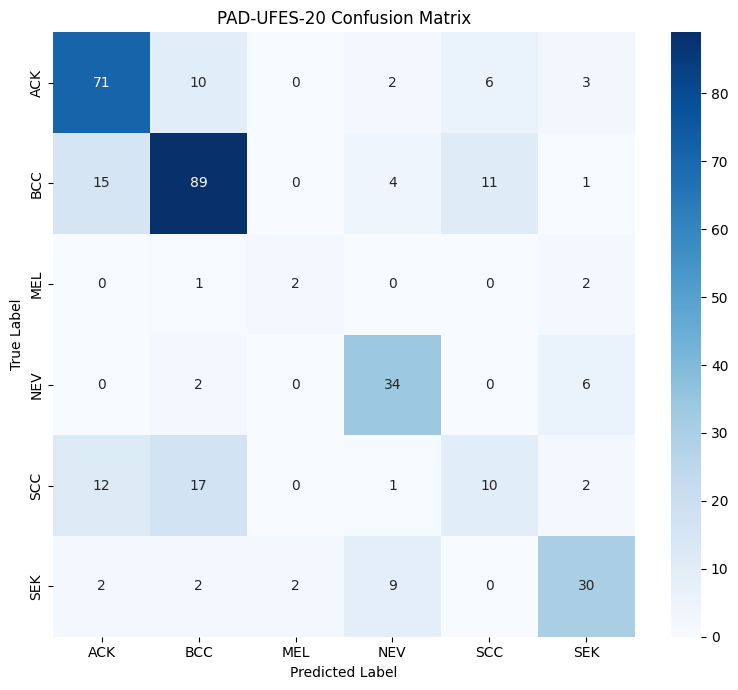

In [89]:
# ============================================================
# BLOCK 25 : CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(8, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("PAD-UFES-20 Confusion Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(
        SAVE_DIR,
        "Confusion_Matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [90]:
# ============================================================
# BLOCK 26 : CLASSIFICATION REPORT + METRICS
# ============================================================

print("=" * 60)
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("=" * 60)

Classification Report
              precision    recall  f1-score   support

         ACK     0.7100    0.7717    0.7396        92
         BCC     0.7355    0.7417    0.7386       120
         MEL     0.5000    0.4000    0.4444         5
         NEV     0.6800    0.8095    0.7391        42
         SCC     0.3704    0.2381    0.2899        42
         SEK     0.6818    0.6667    0.6742        45

    accuracy                         0.6821       346
   macro avg     0.6130    0.6046    0.6043       346
weighted avg     0.6673    0.6821    0.6718       346


Accuracy  : 0.6821
Precision : 0.6673
Recall    : 0.6821
F1-score  : 0.6718


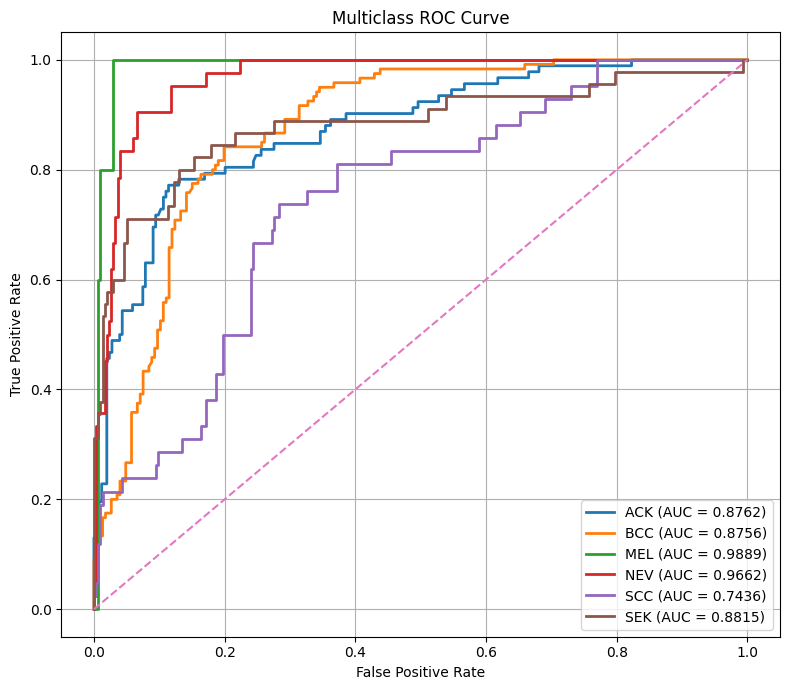


AUC Scores:
ACK: 0.8762
BCC: 0.8756
MEL: 0.9889
NEV: 0.9662
SCC: 0.7436
SEK: 0.8815


In [91]:
# ============================================================
# BLOCK 27 : MULTICLASS ROC CURVES
# ============================================================

from sklearn.preprocessing import label_binarize

NUM_CLASSES = len(class_names)

# Convert true labels to binary format
y_true_bin = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

auc_scores = {}

plt.figure(
    figsize=(8, 7)
)

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_pred_prob[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    auc_scores[class_name] = roc_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve")

plt.legend(
    loc="lower right"
)

plt.grid(True)
plt.tight_layout()
plt.show()

print("\nAUC Scores:")

for class_name, score in auc_scores.items():
    print(
        f"{class_name}: {score:.4f}"
    )

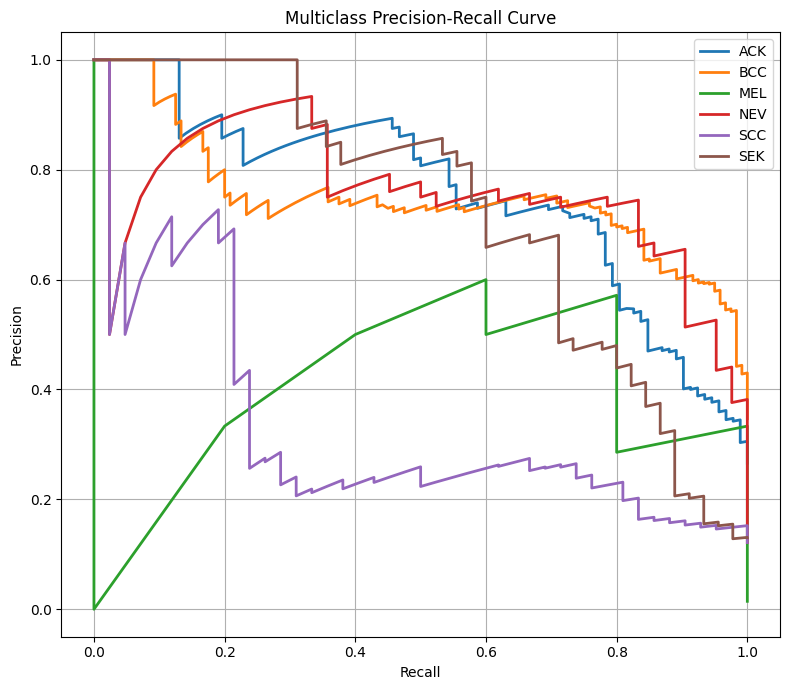

In [92]:
# ============================================================
# BLOCK 28 : PRECISION-RECALL CURVES
# ============================================================

plt.figure(
    figsize=(8, 7)
)

for i, class_name in enumerate(class_names):

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true_bin[:, i],
        y_pred_prob[:, i]
    )

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=class_name
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Multiclass Precision-Recall Curve")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

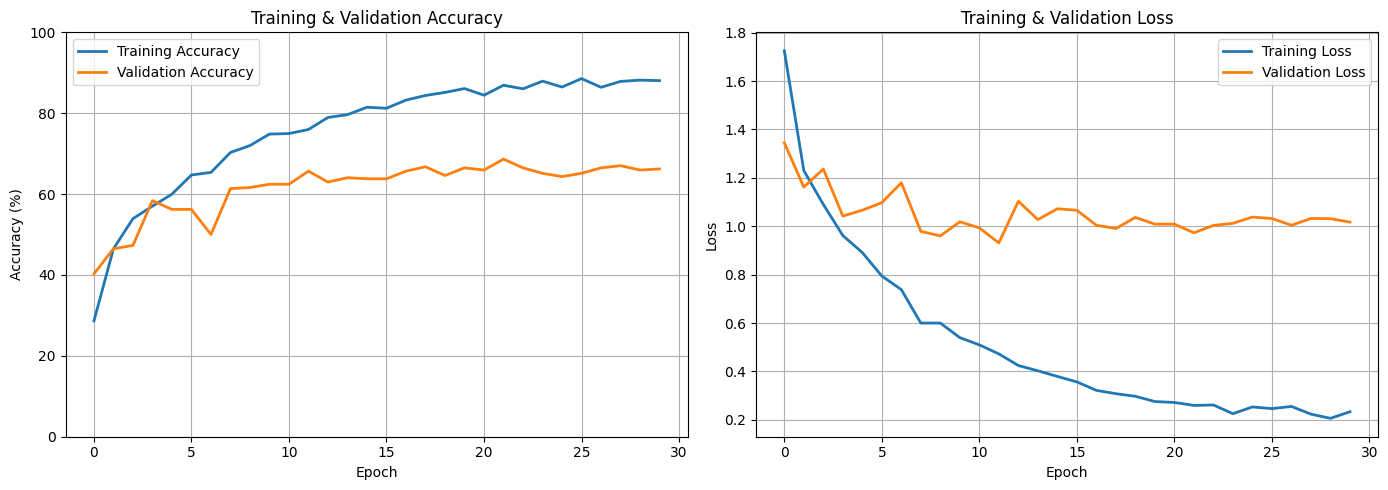

In [93]:
# ============================================================
# BLOCK 29 : TRAINING & VALIDATION CURVES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# ACCURACY
# ------------------------------------------------------------

train_acc = np.array(
    history.history["accuracy"]
) * 100

val_acc = np.array(
    history.history["val_accuracy"]
) * 100

axes[0].plot(
    train_acc,
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    val_acc,
    label="Validation Accuracy",
    linewidth=2
)

axes[0].set_title(
    "Training & Validation Accuracy"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Accuracy (%)"
)

axes[0].set_ylim(
    0,
    100
)

axes[0].legend()
axes[0].grid(True)

# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

axes[1].plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].set_title(
    "Training & Validation Loss"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Loss"
)

axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [94]:
# ============================================================
# BLOCK 30 : MEDICAL PERFORMANCE METRICS
# ============================================================

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

print("=" * 60)
print("Medical Evaluation Metrics")
print("=" * 60)

print(f"Balanced Accuracy        : {balanced_acc:.4f}")
print(f"Matthews Corrcoef (MCC)  : {mcc:.4f}")
print(f"Cohen's Kappa            : {kappa:.4f}")

print("=" * 60)

Medical Evaluation Metrics
Balanced Accuracy        : 0.6046
Matthews Corrcoef (MCC)  : 0.5818
Cohen's Kappa            : 0.5807


In [95]:
# ============================================================
# BLOCK 31 : PER-CLASS SENSITIVITY & SPECIFICITY
# ============================================================

medical_results = []

for i, class_name in enumerate(class_names):

    TP = cm[i, i]

    FN = np.sum(
        cm[i, :]
    ) - TP

    FP = np.sum(
        cm[:, i]
    ) - TP

    TN = np.sum(cm) - (
        TP + FP + FN
    )

    sensitivity = (
        TP / (TP + FN)
        if (TP + FN) != 0
        else 0
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP) != 0
        else 0
    )

    medical_results.append(
        {
            "Class": class_name,
            "Sensitivity": sensitivity,
            "Specificity": specificity
        }
    )

medical_df = pd.DataFrame(
    medical_results
)

print(medical_df)

  Class  Sensitivity  Specificity
0   ACK     0.771739     0.885827
1   BCC     0.741667     0.858407
2   MEL     0.400000     0.994135
3   NEV     0.809524     0.947368
4   SCC     0.238095     0.944079
5   SEK     0.666667     0.953488


In [96]:
# ============================================================
# BLOCK 32 : SAVE ALL PERFORMANCE METRICS
# ============================================================

results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Balanced Accuracy",
        "MCC",
        "Cohen Kappa",
        "Test Loss"
    ],

    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        balanced_acc,
        mcc,
        kappa,
        test_loss
    ]
})

results_path = os.path.join(
    SAVE_DIR,
    "Performance_Metrics.xlsx"
)

results.to_excel(
    results_path,
    index=False
)

medical_results_path = os.path.join(
    SAVE_DIR,
    "Per_Class_Medical_Metrics.xlsx"
)

medical_df.to_excel(
    medical_results_path,
    index=False
)

print("Performance metrics saved successfully ✅")

print("\nOverall Metrics:")
print(results)

print("\nPer-Class Medical Metrics:")
print(medical_df)

Performance metrics saved successfully ✅

Overall Metrics:
              Metric     Value
0           Accuracy  0.682081
1          Precision  0.667289
2             Recall  0.682081
3           F1-score  0.671818
4  Balanced Accuracy  0.604615
5                MCC  0.581819
6        Cohen Kappa  0.580662
7          Test Loss  1.205299

Per-Class Medical Metrics:
  Class  Sensitivity  Specificity
0   ACK     0.771739     0.885827
1   BCC     0.741667     0.858407
2   MEL     0.400000     0.994135
3   NEV     0.809524     0.947368
4   SCC     0.238095     0.944079
5   SEK     0.666667     0.953488
